# POD reduced-order models of the lid-driven cavity — all figures

This notebook draws every figure in the README from the saved results in `results/`.

* `RUN_ALL = False` (default): use the saved results (seconds).
* `RUN_ALL = True`: rerun the tests, the full-order solver, the steady sweep and all three stages first (about 30 min on 2 cores; writes about 1.4 GB to `data/`).

Figures are also written to `figures/`.

In [1]:
import os, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
from src import plots

RUN_ALL = False
FIG = os.path.join(ROOT, 'figures')
need = [os.path.join(ROOT, 'results', f) for f in ('stage1.npz', 'stage2.npz', 'stage3.npz', 'stage4.npz', 'stage4_nu.npz')]
if RUN_ALL or not all(os.path.exists(f) for f in need):
    subprocess.run(['bash', os.path.join(ROOT, 'scripts', 'run_all.sh')], check=True)

r1, r2, r3, r4, r4n = (dict(np.load(f)) for f in need)
%matplotlib inline

## Stage 1 — intrusive POD-Galerkin ROM, transient Re = 100

### How long is the transient?

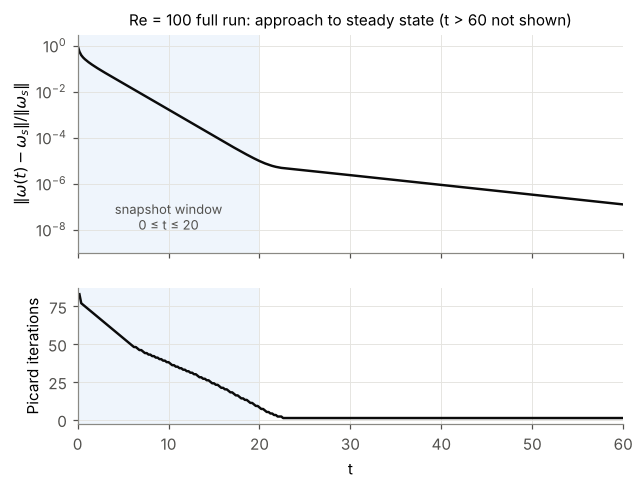

In [2]:
plots.s1_steady_approach(r1, FIG); plt.show()

### POD spectrum and modes

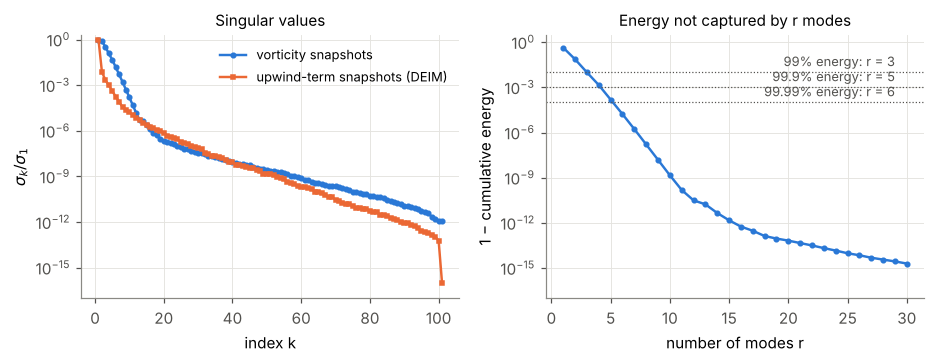

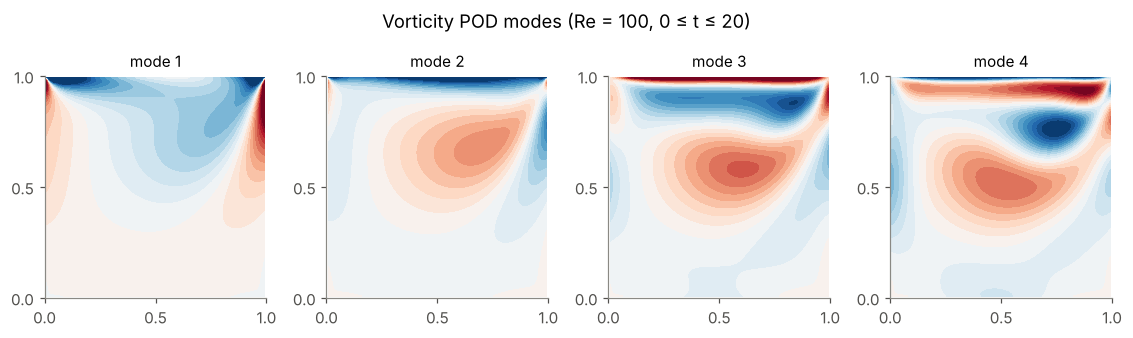

In [3]:
plots.s1_pod_spectrum(r1, FIG); plt.show()
plots.mode_panels(list(r1['modes']), [f'mode {k+1}' for k in range(4)], 128, FIG, 's1_modes.png',
                  'Vorticity POD modes (Re = 100, 0 ≤ t ≤ 20)'); plt.show()

### Error over time, error and speed-up versus r

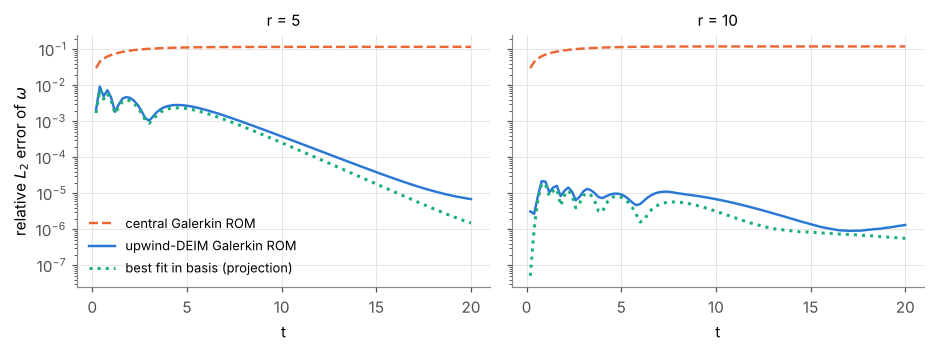

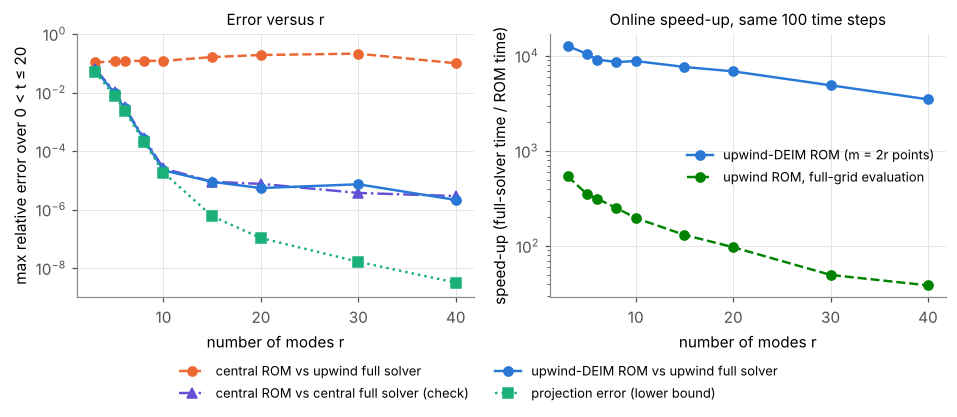

In [4]:
plots.s1_error_vs_time(r1, FIG); plt.show()
plots.s1_error_vs_r(r1, FIG); plt.show()

### Centreline velocities

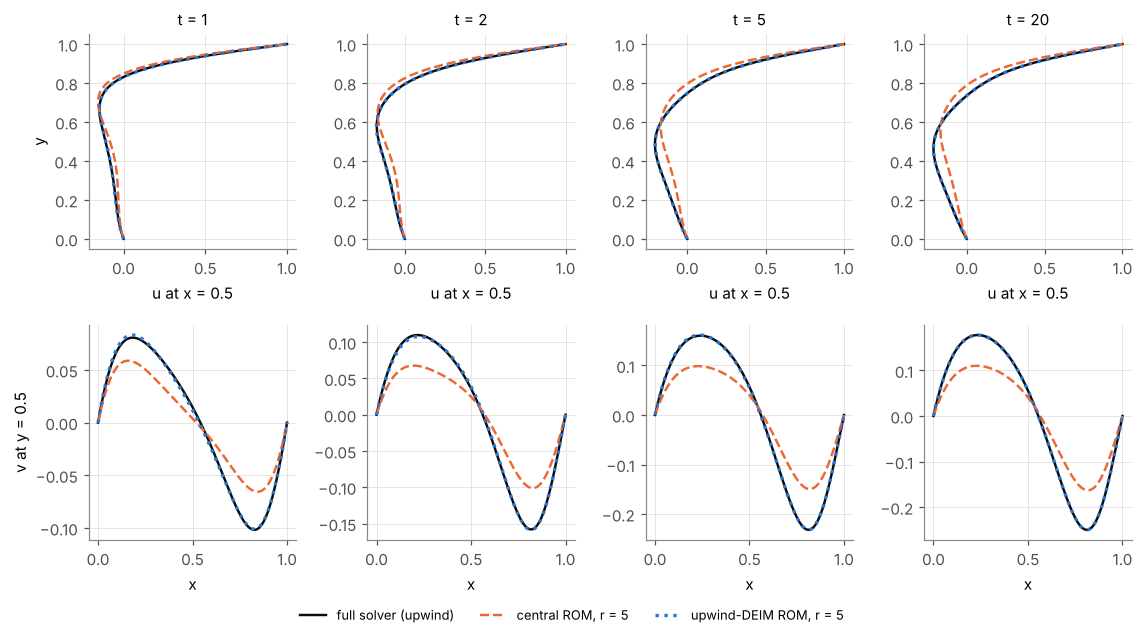

In [5]:
plots.s1_centrelines(r1, FIG); plt.show()

### Long-time run and other Reynolds numbers

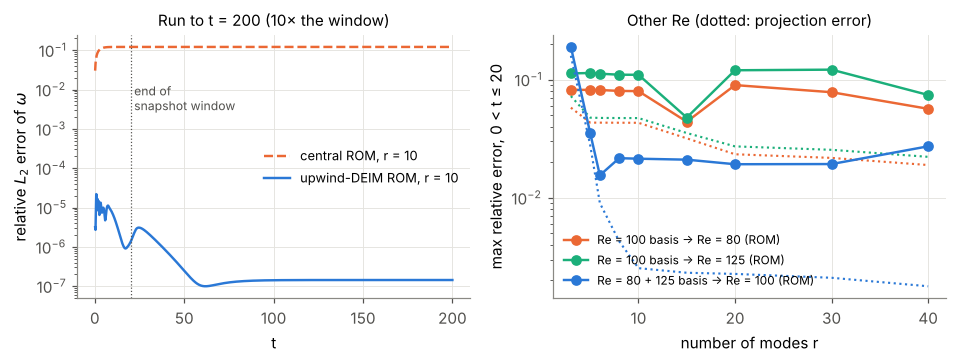

In [6]:
plots.s1_generalisation(r1, FIG); plt.show()

## Stage 2 — non-intrusive parametric POD over Re (steady)

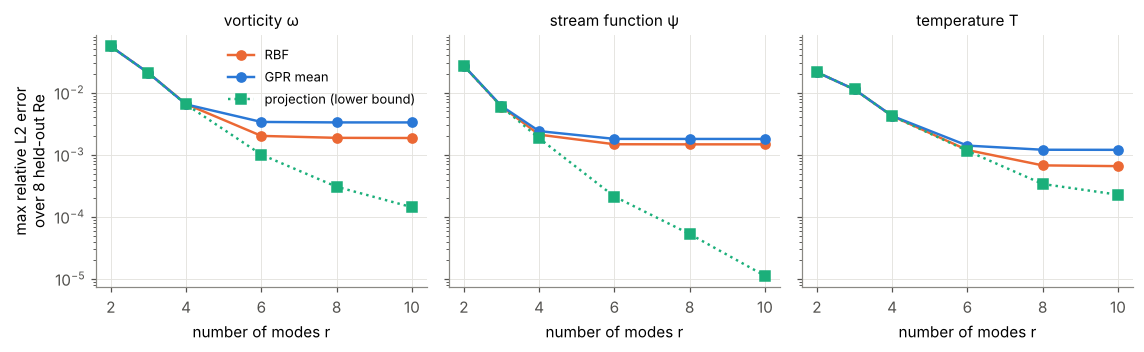

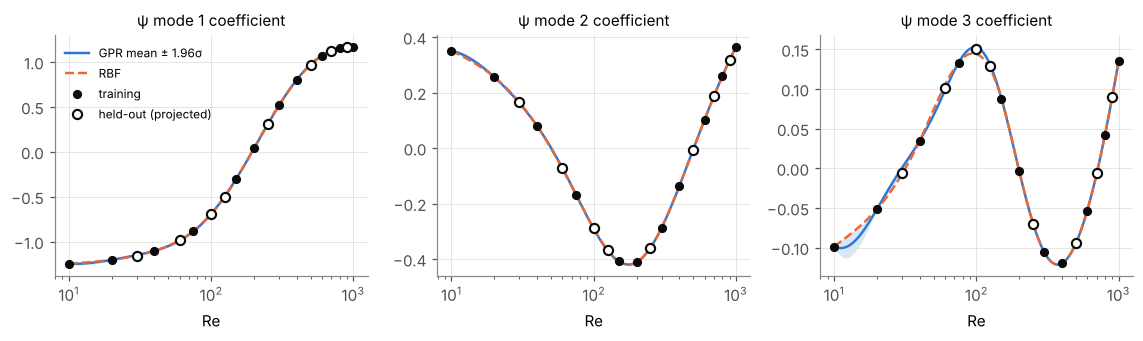

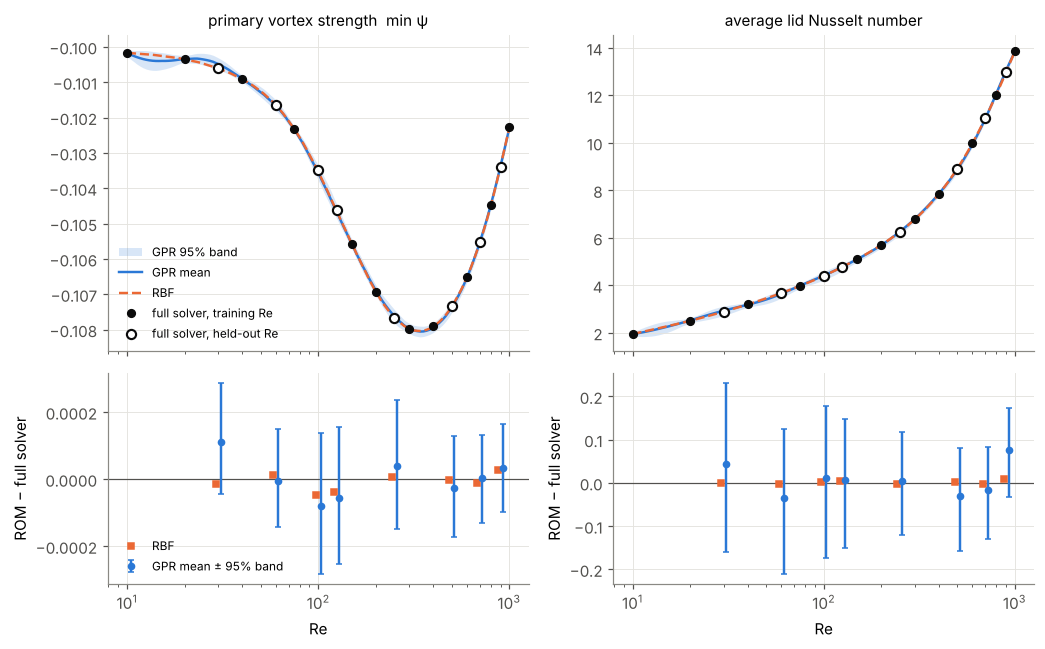

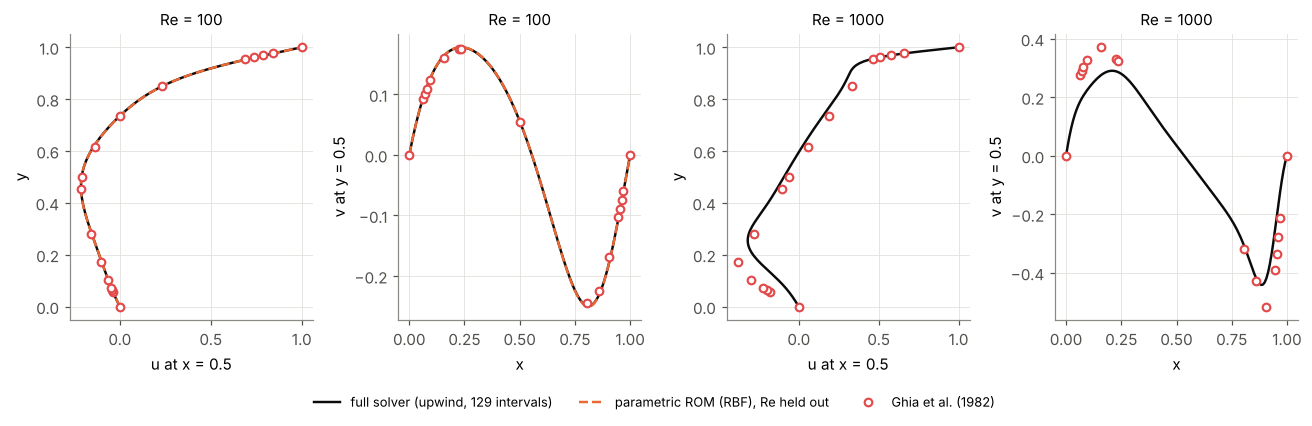

In [7]:
plots.s2_field_error_vs_r(r2, FIG); plt.show()
plots.s2_coefficients(r2, FIG); plt.show()
plots.s2_qoi(r2, FIG); plt.show()
plots.s2_ghia(r2, FIG); plt.show()

## Stage 3 — temperature POD and coupled thermal ROM

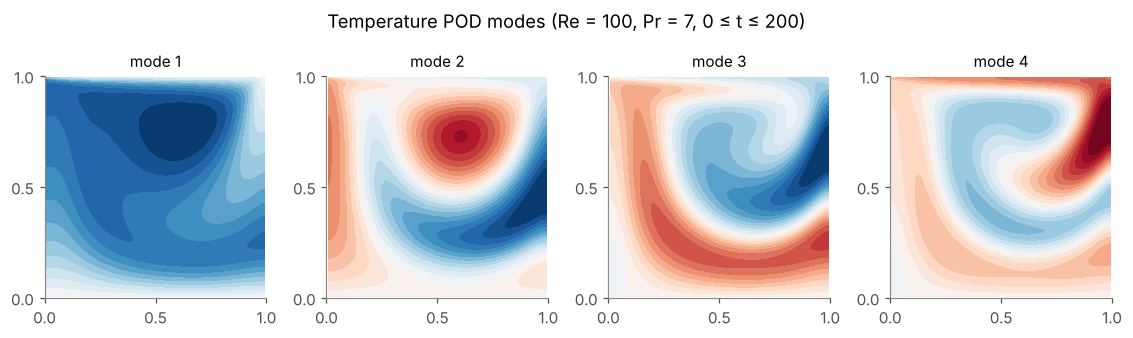

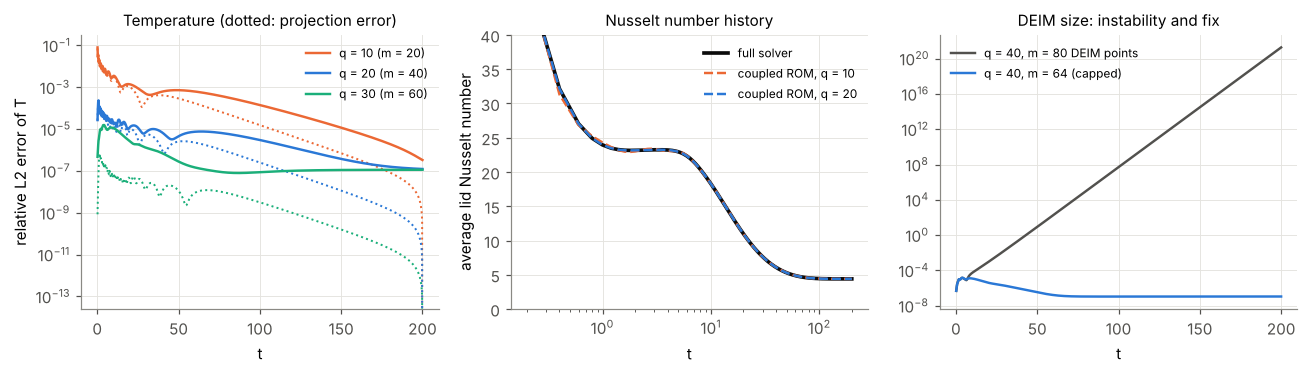

In [8]:
plots.mode_panels(list(r3['T_modes']), [f'mode {k+1}' for k in range(4)], 128, FIG, 's3_T_modes.png',
                  'Temperature POD modes (Re = 100, Pr = 7, 0 ≤ t ≤ 200)'); plt.show()
plots.s3_thermal(r3, FIG); plt.show()

## Stage 4 — adapting the basis to an unseen Re (ORBI, ITSGM, global basis)

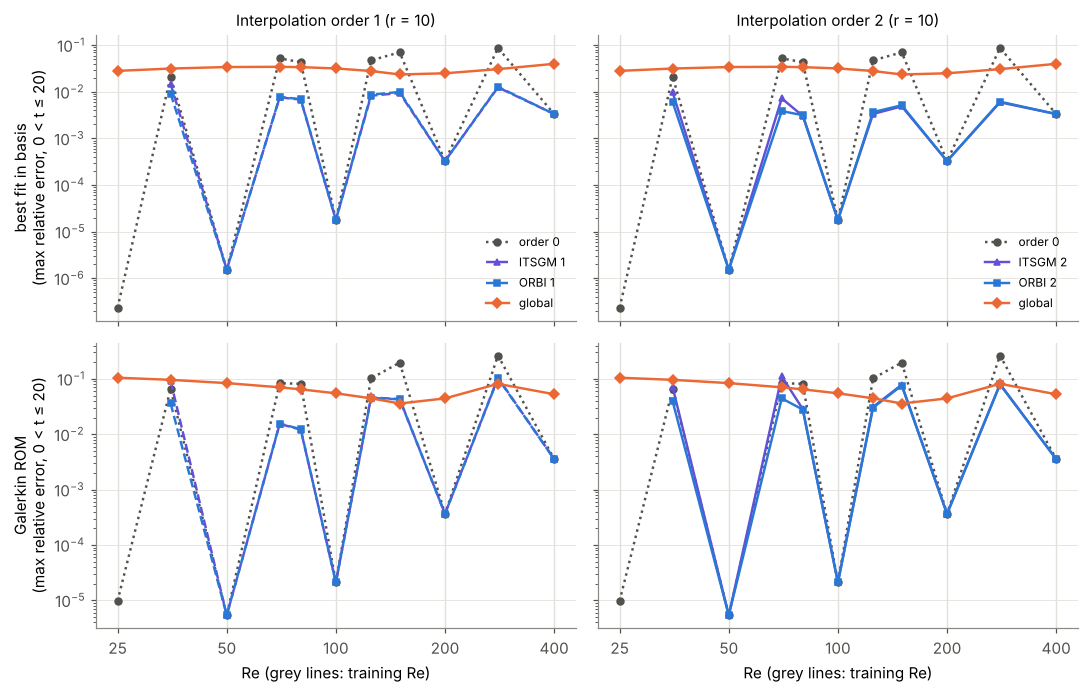

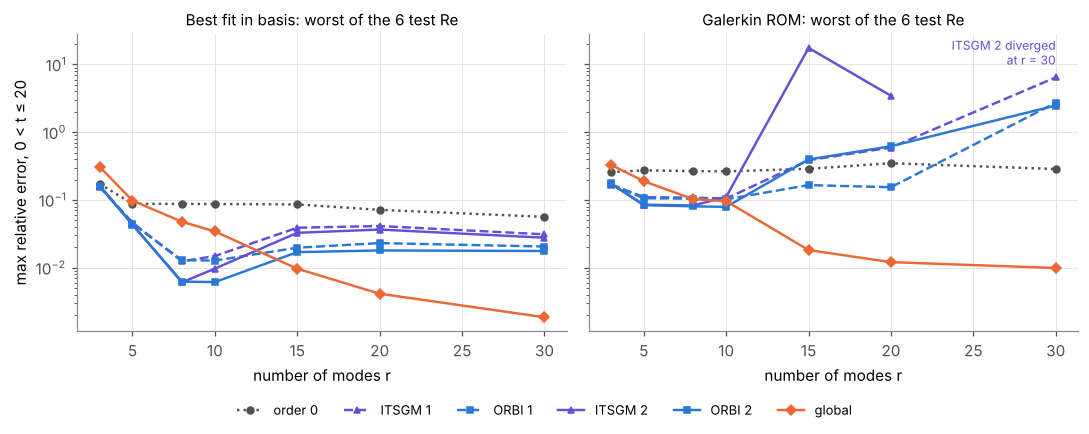

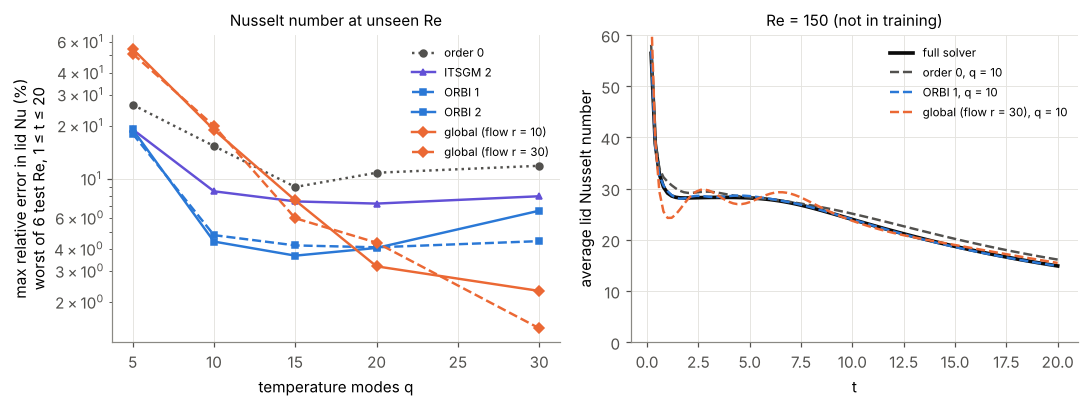

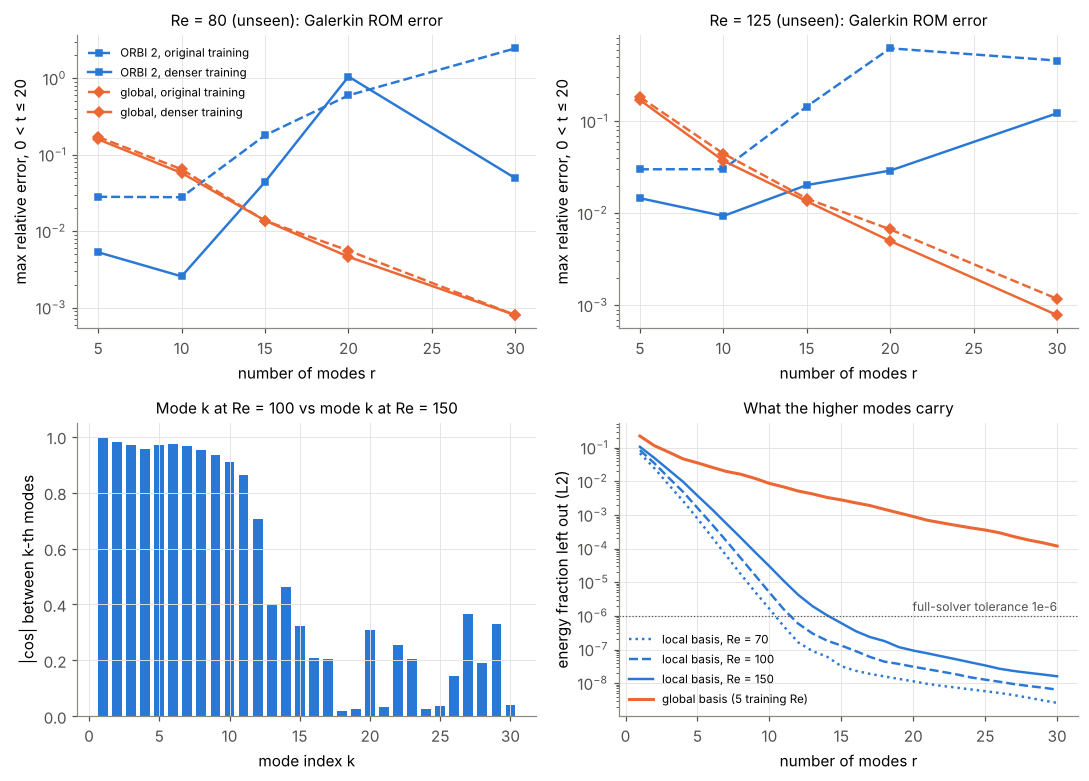

In [9]:
plots.s4_error_vs_Re(r4, FIG); plt.show()
plots.s4_error_vs_r(r4, FIG); plt.show()
plots.s4_nusselt(r4n, FIG); plt.show()
r4d = dict(np.load(os.path.join(ROOT, 'results', 'stage4_dense.npz')))
plots.s4_dense(r4d, FIG); plt.show()

## Results tables (the numbers in the README)

In [10]:
print(subprocess.run([sys.executable, os.path.join(ROOT, 'scripts', 'make_tables.py')],
                     capture_output=True, text=True, check=True).stdout)

Full solver, steps 1-100 (0 < t <= 20): 217.2 s; whole run 350.6 s
r for 99/99.9/99.99% energy: [3, 5, 6]; SVD vs method of snapshots (first 10 sigma): 6.0e-10
Steady states, upwind vs central: 1.93 %; min psi upwind -0.103486, central -0.103331
Offline: Galerkin tensors (r=40) 0.47 s, DEIM snapshots+POD 0.42 s

| r | projection error | central ROM | upwind-DEIM ROM (m = 2r) | DEIM ROM time | speed-up |
|---|---|---|---|---|---|
| 3 | 5.0e-02 | 1.1e-01 | 6.1e-02 | 17.1 ms | 12,706× |
| 5 | 7.6e-03 | 1.2e-01 | 9.3e-03 | 20.7 ms | 10,510× |
| 6 | 2.4e-03 | 1.2e-01 | 2.9e-03 | 23.7 ms | 9,170× |
| 8 | 2.1e-04 | 1.2e-01 | 2.5e-04 | 25.2 ms | 8,629× |
| 10 | 1.8e-05 | 1.2e-01 | 2.2e-05 | 24.6 ms | 8,833× |
| 15 | 5.9e-07 | 1.6e-01 | 8.9e-06 | 28.4 ms | 7,659× |
| 20 | 1.1e-07 | 1.9e-01 | 5.4e-06 | 31.6 ms | 6,883× |
| 30 | 1.6e-08 | 2.1e-01 | 7.3e-06 | 44.2 ms | 4,911× |
| 40 | 3.2e-09 | 1.0e-01 | 2.1e-06 | 62.1 ms | 3,496× |

Check: central ROM vs central full solver, max error: r=3: 6.4e-